# Lab 3 - Supervised vs Unsupervised Anomaly Detection

Notebook structure follows the assignment tasks. Training runs are numbered as in `LOGBOOK.md`; answers are in `NOTES.md`.

In [12]:
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_columns', 60)

TRAIN_PATH, TEST_PATH = 'Lab3_train.csv', 'Lab3_test.csv'
train_raw = pd.read_csv(TRAIN_PATH)
test_raw  = pd.read_csv(TEST_PATH)
print('train', train_raw.shape, '| test', test_raw.shape)

train (18831, 43) | test (5826, 43)


## Task 1 - The data from a domain-expert perspective

### Task 1.1 - Explore the dataset

In [13]:
LABEL, BIN = 'label', 'binary_label'
FEATURES = [c for c in train_raw.columns if c not in (LABEL, BIN)]
CAT_COLS = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(train_raw[c])]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
BIN01_COLS = [c for c in NUM_COLS if set(train_raw[c].unique()) <= {0, 1}]
print(f'{len(FEATURES)} features: {len(CAT_COLS)} categorical, {len(NUM_COLS)} numerical (0/1 counted as numerical)')
print('Categorical:', CAT_COLS)
print('0/1 numerical:', BIN01_COLS)
for c in CAT_COLS:
    unseen = sorted(set(test_raw[c]) - set(train_raw[c]))
    print(f'{c}: {train_raw[c].nunique()} levels in train, {test_raw[c].nunique()} in test; unseen in test: {unseen}')

41 features: 3 categorical, 38 numerical (0/1 counted as numerical)
Categorical: ['protocol_type', 'service', 'flag']
0/1 numerical: ['land', 'urgent', 'logged_in', 'root_shell', 'num_shells', 'num_outbound_cmds', 'is_host_login', 'is_guest_login']
protocol_type: 3 levels in train, 3 in test; unseen in test: []
service: 65 levels in train, 61 in test; unseen in test: ['tftp_u', 'tim_i']
flag: 11 levels in train, 11 in test; unseen in test: []


In [14]:
def label_table(df):
    t = pd.DataFrame({'count': df[LABEL].value_counts(), '%': (df[LABEL].value_counts(normalize=True)*100).round(2)})
    return t

dist = pd.concat({'train': label_table(train_raw), 'test': label_table(test_raw)}, axis=1).fillna(0)
display(dist)
for name, df in [('train', train_raw), ('test', test_raw)]:
    n_anom = df[BIN].sum()
    print(f'{name}: normal={len(df)-n_anom}, anomalous={n_anom}, anomaly fraction={n_anom/len(df):.4f}')
    # consistency between attack label and binary label
    assert ((df[LABEL] != 'normal').astype(int) == df[BIN]).all()

train           test       
        count      %   count      %
label                              
normal  13448  71.41  2152.0  36.94
dos      2913  15.47  2577.0  44.23
probe    2289  12.16  1097.0  18.83
r2l       181   0.96     0.0   0.00

train: normal=13448, anomalous=5383, anomaly fraction=0.2859
test: normal=2152, anomalous=3674, anomaly fraction=0.6306


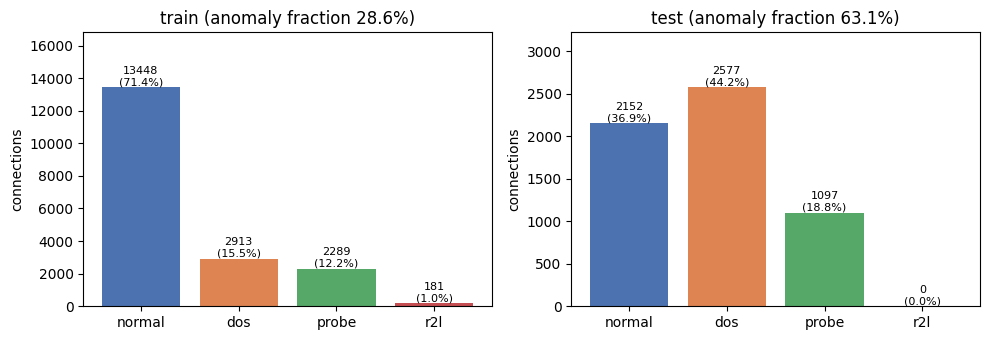

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
order = ['normal', 'dos', 'probe', 'r2l']
for ax, (name, df) in zip(axes, [('train', train_raw), ('test', test_raw)]):
    vc = df[LABEL].value_counts().reindex(order, fill_value=0)
    ax.bar(vc.index, vc.values, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
    for i, v in enumerate(vc.values):
        ax.text(i, v, f'{v}\n({v/len(df):.1%})', ha='center', va='bottom', fontsize=8)
    ax.set_title(f'{name} (anomaly fraction {df[BIN].mean():.1%})'); ax.set_ylabel('connections')
    ax.set_ylim(0, vc.max()*1.25)
plt.tight_layout(); plt.show()

In [16]:
# Data quality checks (no rows are modified here)
for name, df in [('train', train_raw), ('test', test_raw)]:
    num = df[NUM_COLS]
    print(f'{name}: missing={df.isna().sum().sum()}, inf={np.isinf(num).sum().sum()}, '
          f'negative={(num < 0).sum().sum()}, duplicate rows={df.duplicated().sum()}, '
          f'duplicate feature vectors={df[FEATURES].duplicated().sum()}')
    print('   constant numerical columns:', [c for c in NUM_COLS if df[c].nunique() == 1])
conf = train_raw[train_raw.duplicated(FEATURES, keep=False)]
print('\nFeature vectors with conflicting labels in train:'); display(conf[['protocol_type','service','flag','src_bytes',LABEL]])
overlap = test_raw.merge(train_raw, how='inner', on=list(train_raw.columns))
print('Test rows identical to a training row:', len(overlap))

train: missing=0, inf=0, negative=0, duplicate rows=0, duplicate feature vectors=1
   constant numerical columns: ['urgent', 'num_outbound_cmds', 'is_host_login']
test: missing=0, inf=0, negative=0, duplicate rows=0, duplicate feature vectors=0
   constant numerical columns: ['land', 'urgent', 'num_shells', 'num_outbound_cmds', 'is_host_login']

Feature vectors with conflicting labels in train:


,protocol_type,service,flag,src_bytes,label
8087,icmp,ecr_i,SF,20,probe
8800,icmp,ecr_i,SF,20,normal


Test rows identical to a training row: 75


In [17]:
print('Protocol by label (train):'); display(pd.crosstab(train_raw[LABEL], train_raw['protocol_type']))
print('Heavy-tailed numerical features (train):')
display(train_raw[NUM_COLS].describe().T.query('max > 1')[['mean','50%','max']].sort_values('max', ascending=False))

Protocol by label (train):


protocol_type,icmp,tcp,udp
label,,,
dos,529,2196,188
normal,261,10680,2507
probe,827,1147,315
r2l,0,181,0


Heavy-tailed numerical features (train):


,mean,50%,max
src_bytes,32545.325155,207.0,381709090.0
dst_bytes,3238.092719,136.0,5131424.0
duration,407.959057,0.0,42862.0
num_root,0.330253,0.0,975.0
num_compromised,0.301630,0.0,884.0
count,55.027508,6.0,511.0
srv_count,33.330891,6.0,511.0
dst_host_count,161.085126,222.0,255.0
dst_host_srv_count,149.129149,188.0,255.0
hot,0.261324,0.0,77.0


### Task 1.2 - Preprocessing

Decisions (justified in NOTES):
1. Drop numerical columns that are constant in **train** (no information, they would only add zero-variance dimensions).
2. Categorical: one-hot encoding fitted on train. `service` levels with < 10 training rows are merged into one *infrequent* column; categories unseen in train (`tftp_u`, `tim_i` in test) also map to it instead of producing an all-zero vector.
3. Numerical: `log1p` on non-rate counters/byte counts with training skewness > 2 (rule decided on train only), then `MinMaxScaler` on all numerical columns, so every feature (rates, 0/1 indicators, one-hot, counters) lives on a comparable [0, 1] scale. We first tried `StandardScaler`: it inflates sparse indicators (e.g. `land`, 1 in ~18.8k rows, reaches 137 standard deviations), so a single rare flag would dominate Euclidean/RBF distances. The comparison is kept below.
4. Every parameter (constant columns, skewness, category levels, min/max) is estimated on **train.csv only** and then applied unchanged to test.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, FunctionTransformer

CONST_COLS = [c for c in NUM_COLS if train_raw[c].nunique() == 1]
NUM_KEEP = [c for c in NUM_COLS if c not in CONST_COLS]
RATE_COLS = [c for c in NUM_KEEP if c.endswith('_rate')]
skew = train_raw[NUM_KEEP].skew()
LOG_COLS = [c for c in NUM_KEEP if c not in RATE_COLS and c not in BIN01_COLS and skew[c] > 2]
LIN_COLS = [c for c in NUM_KEEP if c not in LOG_COLS]
print('Dropped constant:', CONST_COLS)
print(f'log1p + min-max ({len(LOG_COLS)}):', LOG_COLS)
print(f'min-max only ({len(LIN_COLS)}):', LIN_COLS)
display(skew[LOG_COLS + ['count', 'srv_count', 'dst_host_count', 'dst_host_srv_count']].drop_duplicates().round(2).to_frame('train skew'))

Dropped constant: ['urgent', 'num_outbound_cmds', 'is_host_login']
log1p + min-max (13): ['duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'hot', 'num_failed_logins', 'num_compromised', 'su_attempted', 'num_root', 'num_file_creations', 'num_access_files', 'count', 'srv_count']
min-max only (22): ['land', 'logged_in', 'root_shell', 'num_shells', 'is_guest_login', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


,train skew
duration,9.94
src_bytes,136.22
dst_bytes,73.62
wrong_fragment,9.88
hot,11.78
num_failed_logins,58.46
num_compromised,53.81
su_attempted,33.03
num_root,53.95
num_file_creations,47.51


In [19]:
def make_preprocessor(scaler_cls):
    return ColumnTransformer([
        ('log_num', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                              ('scale', scaler_cls())]), LOG_COLS),
        ('num', scaler_cls(), LIN_COLS),
        ('cat', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False), CAT_COLS),
    ], remainder='drop', verbose_feature_names_out=True)

# Rejected alternative: StandardScaler. Inspect how far sparse features are pushed.
_std = make_preprocessor(StandardScaler).fit(train_raw[FEATURES])
_Xs = _std.transform(train_raw[FEATURES])
_names = _std.get_feature_names_out()
print('StandardScaler: largest training values (std units) ->')
display(pd.Series(_Xs.max(0), index=_names).sort_values(ascending=False).head(6).round(1).to_frame('max'))

preprocessor = make_preprocessor(MinMaxScaler)

# Fit on the full training file only (labels are NOT passed); apply unchanged to test.
X_train = preprocessor.fit_transform(train_raw[FEATURES])
X_test  = preprocessor.transform(test_raw[FEATURES])
FEATURE_NAMES = preprocessor.get_feature_names_out()
y_train_bin, y_test_bin = train_raw[BIN].to_numpy(), test_raw[BIN].to_numpy()
y_train_lab, y_test_lab = train_raw[LABEL].to_numpy(), test_raw[LABEL].to_numpy()

n_cat = sum(n.startswith('cat__') for n in FEATURE_NAMES)
print('X_train', X_train.shape, '| X_test', X_test.shape, f'| {X_train.shape[1]-n_cat} numerical + {n_cat} one-hot')
print('one-hot per column:', {c: sum(n.startswith(f'cat__{c}_') for n in FEATURE_NAMES) for c in CAT_COLS})
print('infrequent service levels:', preprocessor.named_transformers_['cat'].infrequent_categories_[1])
for name, raw in [('test', test_raw)]:
    unseen = raw['service'].isin(['tftp_u', 'tim_i']).to_numpy()
    print('unseen test rows -> infrequent column:', X_test[unseen][:, list(FEATURE_NAMES).index('cat__service_infrequent_sklearn')])
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

StandardScaler: largest training values (std units) ->


,max
num__land,137.2
log_num__num_failed_logins,65.8
num__num_shells,48.5
log_num__num_access_files,40.3
log_num__num_file_creations,40.1
log_num__num_compromised,34.5


X_train (18831, 106) | X_test (5826, 106) | 35 numerical + 71 one-hot
one-hot per column: {'protocol_type': 3, 'service': 57, 'flag': 11}
infrequent service levels: ['http_8001' 'pm_dump' 'pop_2' 'printer' 'red_i' 'remote_job' 'rje'
 'shell' 'urh_i']
unseen test rows -> infrequent column: [1. 1.]


MinMax: train range is [0, 1] by construction; test values outside [0, 1]: 7


,train mean,test mean,test min,test max
log_num__duration,0.042,0.010,0.000,1.022
log_num__hot,0.011,0.018,0.000,1.062
log_num__num_file_creations,0.001,0.000,0.000,1.243
log_num__count,0.309,0.596,-0.125,1.000
log_num__srv_count,0.270,0.362,-0.125,1.000


Largest train->test mean shifts (larger dos share in test):


num__logged_in                 0.400
log_num__count                 0.287
num__dst_host_count            0.269
num__same_srv_rate             0.241
num__dst_host_same_srv_rate    0.199
num__dst_host_rerror_rate      0.192
Name: shift, dtype: float64

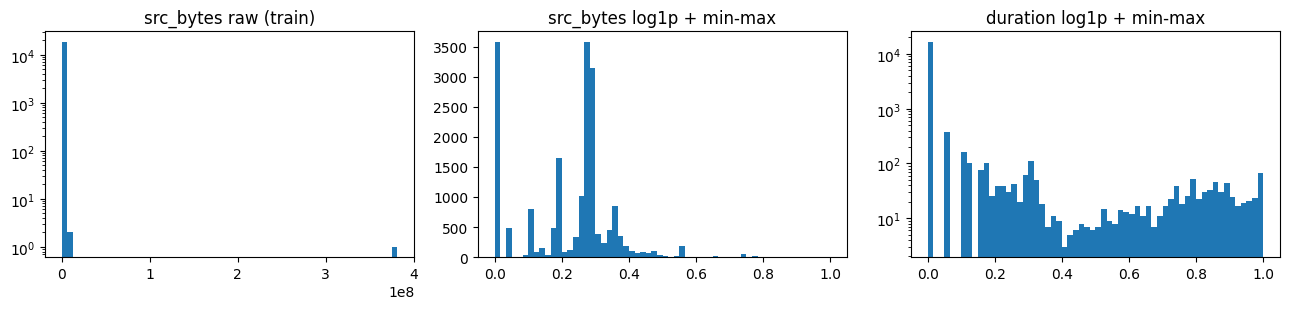

In [20]:
num_idx = [i for i, n in enumerate(FEATURE_NAMES) if not n.startswith('cat__')]
summ = pd.DataFrame({'train mean': X_train[:, num_idx].mean(0), 'test mean': X_test[:, num_idx].mean(0),
                     'test min': X_test[:, num_idx].min(0), 'test max': X_test[:, num_idx].max(0)},
                    index=FEATURE_NAMES[num_idx]).round(3)
print('MinMax: train range is [0, 1] by construction; test values outside [0, 1]:',
      int(((X_test[:, num_idx] < 0) | (X_test[:, num_idx] > 1)).sum()))
display(summ[(summ['test max'] > 1) | (summ['test min'] < 0)])
summ['shift'] = (summ['test mean'] - summ['train mean'])
print('Largest train->test mean shifts (larger dos share in test):')
display(summ['shift'].abs().sort_values(ascending=False).head(6).round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(train_raw['src_bytes'], bins=60); axes[0].set_yscale('log'); axes[0].set_title('src_bytes raw (train)')
i = list(FEATURE_NAMES).index('log_num__src_bytes')
axes[1].hist(X_train[:, i], bins=60); axes[1].set_title('src_bytes log1p + min-max')
j = list(FEATURE_NAMES).index('log_num__duration')
axes[2].hist(X_train[:, j], bins=60); axes[2].set_yscale('log'); axes[2].set_title('duration log1p + min-max')
plt.tight_layout(); plt.show()

### Task 1.3 - Domain-expert heatmaps

Rows: attack labels (train). Columns: the 35 numerical features **after** Task 1.2 (38 numerical attributes minus the 3 constant in train) (`log1p` + min-max), so all features share one [0, 1] colour scale; on raw values `src_bytes` (up to 3.8e8) would flatten every other column. Labels are used here only for exploration.

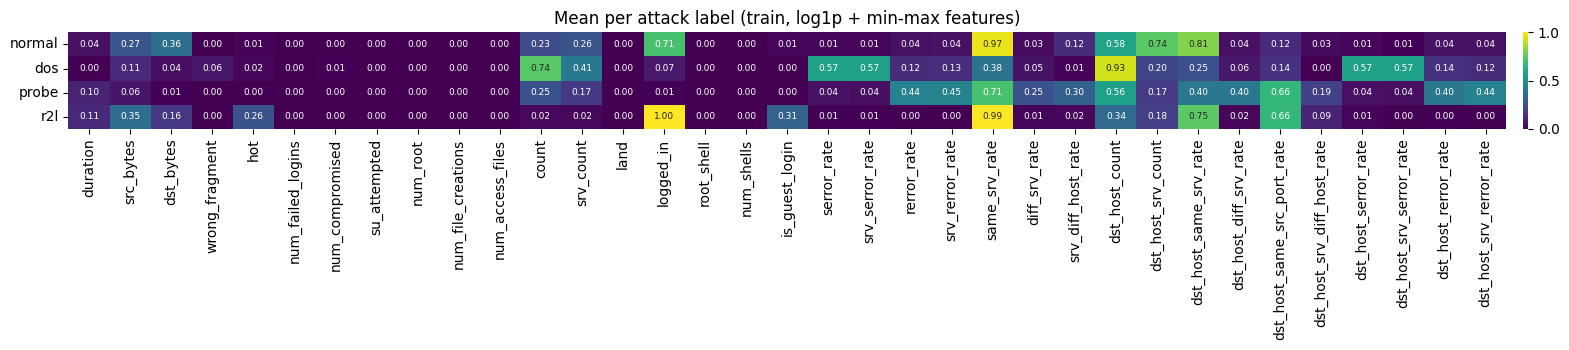

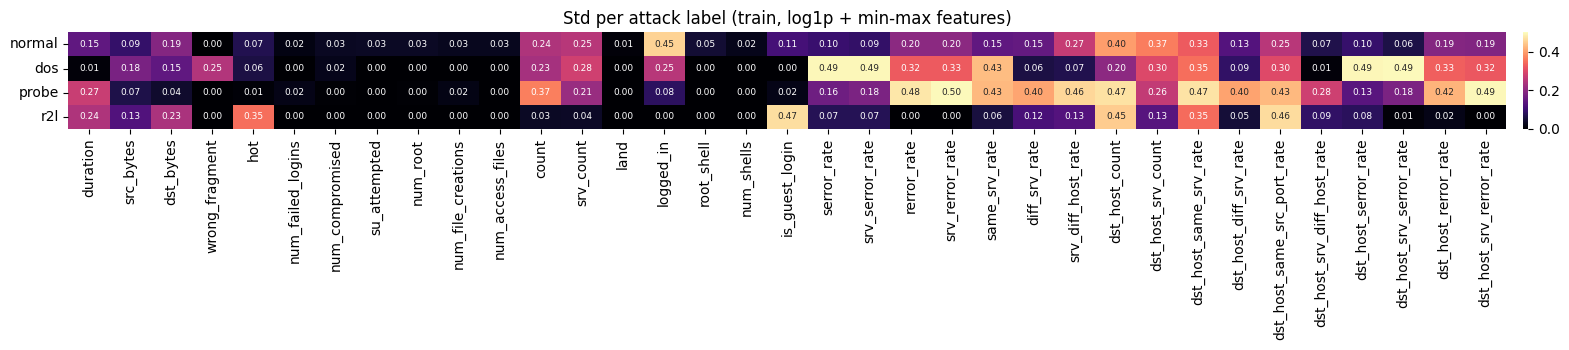

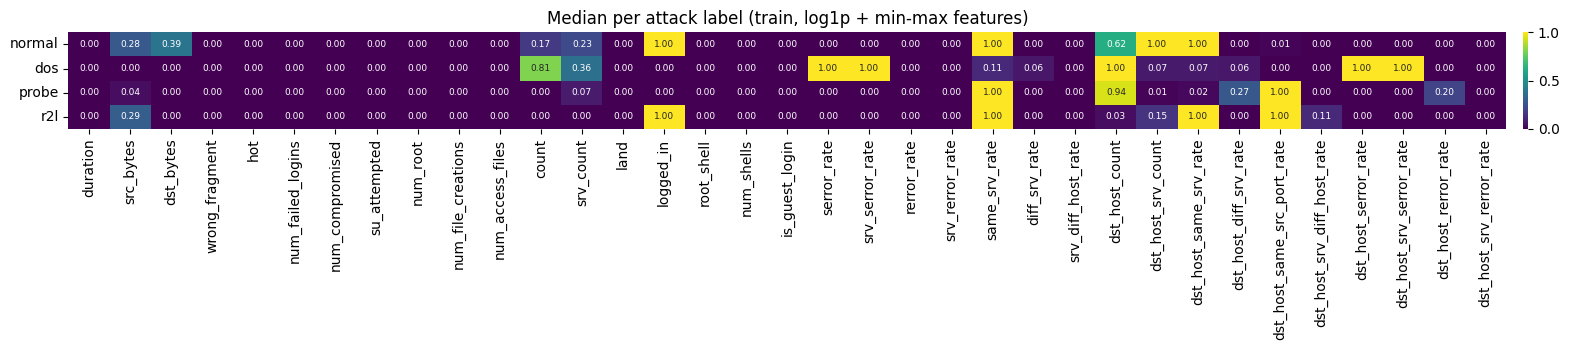

In [21]:
NUM_OUT = [n for n in FEATURE_NAMES if not n.startswith('cat__')]
num_df = pd.DataFrame(X_train[:, [list(FEATURE_NAMES).index(n) for n in NUM_OUT]],
                      columns=[n.split('__', 1)[1] for n in NUM_OUT])
num_df[LABEL] = y_train_lab
ORDER = ['normal', 'dos', 'probe', 'r2l']
stats = {k: num_df.groupby(LABEL).agg(k).reindex(ORDER) for k in ['mean', 'std', 'median']}

for k, cmap in [('mean', 'viridis'), ('std', 'magma'), ('median', 'viridis')]:
    fig, ax = plt.subplots(figsize=(18, 3.6))
    sns.heatmap(stats[k], cmap=cmap, vmin=0, vmax=1 if k != 'std' else 0.5, annot=True, fmt='.2f',
                annot_kws={'size': 6.5}, cbar_kws={'pad': 0.01}, ax=ax)
    ax.set_title(f'{k.capitalize()} per attack label (train, log1p + min-max features)')
    ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(axis='y', rotation=0)
    plt.tight_layout(); plt.show()

In [22]:
# Features whose mean differs most from normal, per attack
diff = stats['mean'].sub(stats['mean'].loc['normal'], axis=1).drop('normal')
for lab in diff.index:
    top = diff.loc[lab].abs().sort_values(ascending=False).head(6).index
    print(f'{lab:5s}:', ', '.join(f'{c} ({diff.loc[lab, c]:+.2f})' for c in top))

dos  : logged_in (-0.64), same_srv_rate (-0.59), dst_host_same_srv_rate (-0.56), dst_host_srv_serror_rate (+0.56), serror_rate (+0.56), dst_host_serror_rate (+0.56)
probe: logged_in (-0.70), dst_host_srv_count (-0.57), dst_host_same_src_port_rate (+0.54), dst_host_same_srv_rate (-0.41), srv_rerror_rate (+0.40), dst_host_srv_rerror_rate (+0.40)
r2l  : dst_host_srv_count (-0.56), dst_host_same_src_port_rate (+0.54), is_guest_login (+0.30), logged_in (+0.29), hot (+0.25), dst_host_count (-0.24)


## Task 2 - One-Class SVM: impact of the anomalies

Labels are used only to build the training subsets and to evaluate. All models: RBF kernel, `gamma='scale'`, same preprocessed features (Task 1.2). Prediction `-1` (outside the boundary) = anomaly.

Evaluation on the training file: **FPR** = fraction of normal training connections flagged as anomalous; **macro-F1** = binary macro-F1 on the **full** train.csv (normal + all attacks), so that also the normal-only models are scored on attacks they never saw; per-attack **recall** = fraction of each attack type flagged.

In [23]:
from sklearn.svm import OneClassSVM
from sklearn.metrics import f1_score, confusion_matrix

ATTACKS = ['dos', 'probe', 'r2l']
RESULTS = {}

def evaluate(pred_anom, y_bin, y_lab):
    """pred_anom: 1 = flagged anomalous. Returns binary macro-F1, FPR and per-attack recall."""
    tn, fp, fn, tp = confusion_matrix(y_bin, pred_anom, labels=[0, 1]).ravel()
    out = {'macro_f1': f1_score(y_bin, pred_anom, average='macro'), 'FPR': fp / (fp + tn),
           'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
    for a in ATTACKS:
        m = y_lab == a
        if m.any(): out[f'recall_{a}'] = pred_anom[m].mean()
    return out

def run_ocsvm(run_id, X_fit, nu, note=''):
    t0 = time.perf_counter()
    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(X_fit)
    fit_s = time.perf_counter() - t0
    pred = (model.predict(X_train) == -1).astype(int)          # scored on the full training file
    res = evaluate(pred, y_train_bin, y_train_lab)
    res.update({'nu': nu, 'n_fit': len(X_fit), 'n_SV': len(model.support_), 'fit_s': fit_s, 'note': note})
    RESULTS[run_id] = res
    print(f'{run_id}: nu={nu:.4f}, n_fit={len(X_fit)}, SV={len(model.support_)} ({len(model.support_)/len(X_fit):.1%}), '
          f'fit {fit_s:.1f}s | FPR={res["FPR"]:.4f}, macro-F1={res["macro_f1"]:.4f}, '
          + ', '.join(f'{a}={res.get(f"recall_{a}", np.nan):.3f}' for a in ATTACKS))
    return model

def results_table(ids):
    cols = ['nu', 'n_fit', 'n_SV', 'FPR', 'macro_f1', 'recall_dos', 'recall_probe', 'recall_r2l', 'FP', 'FN', 'fit_s']
    return pd.DataFrame({k: RESULTS[k] for k in ids}).T[cols]

### Task 2A - Normal traffic only

`nu` is an upper bound on the fraction of training points left outside the boundary (and a lower bound on the fraction of support vectors). With clean normal data every point outside is a false alarm, so `nu` ≈ the training FPR we accept. We choose **`nu = 0.01`**: we tolerate ~1% false alarms (~134 of 13,448 normal connections), enough slack for the rare but legitimate normal patterns seen in Task 1 (rare services, sparse indicators). `nu` cannot be 0: sklearn requires `nu ∈ (0, 1]`, and with `nu → 0` the boundary would have to enclose every training point, including noisy ones.

In [24]:
X_train_normal = X_train[y_train_bin == 0]
print('normal-only training set:', X_train_normal.shape)
ocsvm_run1 = run_ocsvm('run1_normal_nu0.01', X_train_normal, nu=0.01, note='normal only')
ocsvm_run2 = run_ocsvm('run2_normal_nu0.5',  X_train_normal, nu=0.5,  note='normal only, default nu')
display(results_table(['run1_normal_nu0.01', 'run2_normal_nu0.5']).round(4))

normal-only training set: (13448, 106)
run1_normal_nu0.01: nu=0.0100, n_fit=13448, SV=153 (1.1%), fit 0.1s | FPR=0.0104, macro-F1=0.9367, dos=0.910, probe=0.844, r2l=0.017
run2_normal_nu0.5: nu=0.5000, n_fit=13448, SV=6726 (50.0%), fit 5.9s | FPR=0.5000, macro-F1=0.6367, dos=0.974, probe=1.000, r2l=0.994


,nu,n_fit,n_SV,FPR,macro_f1,recall_dos,recall_probe,recall_r2l,FP,FN,fit_s
run1_normal_nu0.01,0.01,13448,153,0.01041,0.936723,0.910058,0.844474,0.016575,140,796,0.132882
run2_normal_nu0.5,0.5,13448,6726,0.5,0.636724,0.97391,0.999563,0.994475,6724,78,5.936365
